# 02 - Model walkthrough: shrinkage, composite score, out-of-time validation, archetypes, exposure
Reads `artifacts/` produced by `make train`.

**Scope:** USAID / PEPFAR SCMS delivery history, one programme, scheduled 2006-2015. The buyer is a US government health-supply programme and deliveries go to PEPFAR countries (not US-domestic). On time = delivered-to-client date <= scheduled date. There is **no vendor hand-off timestamp**. Scores describe recorded delivery performance for this programme, not vendor quality overall, on limited samples.

In [1]:
import os, json, duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
con = duckdb.connect('data/processed/scms.duckdb', read_only=True)
from supplier_risk.shrinkage import BetaPrior, posterior_mean
t = json.load(open('artifacts/train_summary.json'))
sc = pd.read_parquet('artifacts/vendor_scores.parquet')

## 1. Empirical-Bayes priors (maximum marginal likelihood)

In [2]:
pd.DataFrame(t['priors'], index=['a','b','mean','strength']).T

,a,b,mean,strength
late,0.693628,21.381061,0.031422,22.074689
severe,0.646949,34.652597,0.018327,35.299546


In [3]:
p = BetaPrior(*t['priors']['late'][:2])
pd.DataFrame({'n_lines':[1,5,20,100,1000], 'n_late':[1,2,4,20,200]}).assign(
    raw=lambda d: d.n_late/d.n_lines, shrunk=lambda d: posterior_mean(d.n_late, d.n_lines, p))

,n_lines,n_late,raw,shrunk
0,1,1,1.0,0.073398
1,5,2,0.4,0.099489
2,20,4,0.2,0.111555
3,100,20,0.2,0.169516
4,1000,200,0.2,0.196359


A vendor with 1 late line out of 1 is pulled almost entirely to the prior; at 1,000 lines the data dominate.

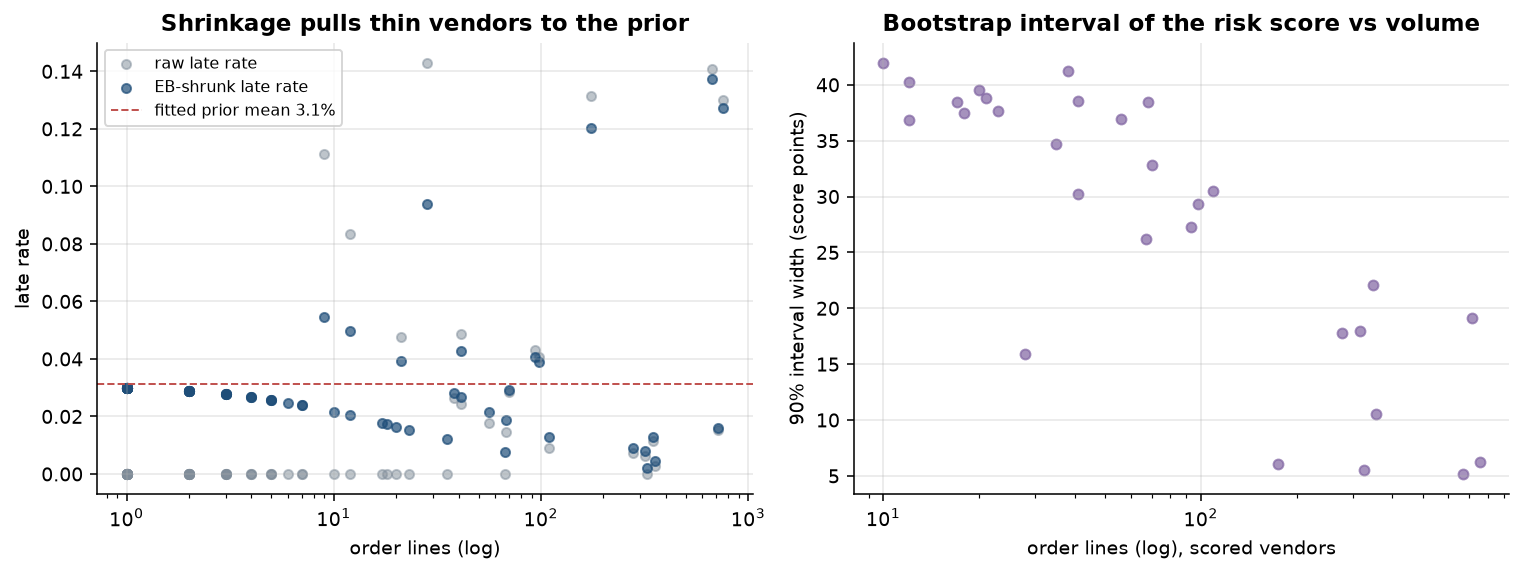

In [4]:
from IPython.display import Image; Image('docs/figures/shrinkage_and_intervals.png', width=850)

## 2. Composite score and tiers (scored vendors have >= 10 lines)

In [5]:
pd.read_csv('artifacts/risk_tier_summary.csv')

,risk_tier,n_vendors,value_usd,late_value_usd,value_at_risk,n_lines,n_late,exposure_ASSUMED,late_rate,value_share,late_value_share
0,Elevated,3,1.558026e+08,26867280.58,1.912142e+07,816.0,101.0,1.024853e+06,0.123775,0.287346,0.475518
1,High,3,1.325358e+08,25231457.04,1.744789e+07,871.0,121.0,1.033355e+06,0.138921,0.244435,0.446566
2,Low,14,2.027668e+08,1898300.01,1.993460e+06,2688.0,22.0,1.136719e+05,0.008185,0.373962,0.033598
3,Moderate,9,4.588359e+07,2499067.86,1.686105e+06,437.0,14.0,9.713039e+04,0.032037,0.084623,0.044230
4,New / unscored,43,5.223230e+06,5028.00,1.645719e+05,108.0,1.0,9.862978e+03,0.009259,0.009633,0.000089


In [6]:
pd.read_csv('artifacts/top_risk_vendors.csv').head(10)

,risk_rank,vendor,top_country,top_product_group,n_lines,value_usd,late_rate_raw,late_rate_shrunk,late_rate_lo90,late_rate_hi90,mean_days_late_shrunk,freight_ratio,risk_score,risk_score_lo90,risk_score_hi90,archetype,value_at_risk
0,1.0,CIPLA LIMITED,South Africa,ARV,175.0,3.965869e+07,0.131429,0.120227,0.084522,0.160319,4.345568,0.050554,82.413793,80.344828,86.379310,Chronic late deliverers,4.768032e+06
1,2.0,Aurobindo Pharma Limited,South Africa,ARV,668.0,9.138371e+07,0.140719,0.137222,0.116305,0.159335,4.515532,0.056339,76.551724,73.103448,78.275862,Chronic late deliverers,1.253988e+07
2,3.0,BIO-RAD LABORATORIES (FRANCE),Côte d'Ivoire,HRDT,28.0,1.493378e+06,0.142857,0.093733,0.037016,0.168915,1.686922,0.129276,76.034483,63.965517,79.836207,Air-dependent,1.399782e+05
3,4.0,EMCURE PHARMACEUTICALS LTD,Rwanda,ARV,41.0,5.756840e+06,0.048780,0.042705,0.010799,0.090884,1.335795,0.045499,72.844828,46.267241,76.465517,Air-dependent,2.458480e+05
4,5.0,Abbott GmbH & Co. KG,Nigeria,HRDT,21.0,2.342400e+06,0.047619,0.039318,0.005736,0.096587,1.683166,0.041143,72.241379,40.336207,79.137931,Air-dependent,9.209942e+04
5,6.0,"Orgenics, Ltd",Nigeria,HRDT,754.0,1.477034e+08,0.129973,0.127170,0.108071,0.147362,1.620971,0.068693,69.655172,66.551724,72.767241,Chronic late deliverers,1.878348e+07
6,7.0,"JSI R&T INSTITUTE, INC.",South Africa,ARV,38.0,2.506896e+05,0.026316,0.028192,0.004079,0.069625,1.880022,0.067189,68.103448,34.974138,76.224138,Surface / truck-based,7.067450e+03
7,8.0,STRIDES ARCOLAB LIMITED,Vietnam,ARV,93.0,2.248547e+07,0.043011,0.040788,0.015741,0.074849,1.071882,0.050149,67.758621,47.215517,74.500000,Air-dependent,9.171296e+05
8,9.0,"SHANGHAI KEHUA BIOENGINEERING CO.,LTD. (KHB)",Ethiopia,HRDT,70.0,7.325764e+06,0.028571,0.029255,0.007341,0.062606,1.358415,0.311626,63.965517,37.758621,70.543103,Air-dependent,2.143139e+05
9,10.0,REINBOLD EXPORT IMPORT,Haiti,HRDT,12.0,1.246105e+06,0.083333,0.049703,0.007307,0.121480,1.067654,0.067189,61.551724,29.991379,66.818966,Unclustered (<20 lines),6.193565e+04


In [7]:
pd.read_csv('artifacts/weight_sensitivity_ranking.csv')

,weights,spearman_vs_base,top5_overlap
0,late_heavy,0.991993,1.0
1,tail_heavy,0.985343,1.0
2,no_lane_context,0.972780,0.8


## 3. Out-of-time validation vs baselines

In [8]:
ev = pd.read_csv('artifacts/oot_metrics_main.csv'); ev.round(3)

,target,score,line_auc,vendor_auc,spearman,lift_top20,capture_top20,late_rate_top20,base_late_rate,n_vendors,n_next_late_lines
0,Late delivery (delivered after scheduled date),Composite risk score (shrunk),0.704,0.762,0.023,1.122,0.194,0.055,0.049,21,108.0
1,Late delivery (delivered after scheduled date),Shrunk late rate (EB) only,0.738,0.810,0.135,2.423,0.889,0.118,0.049,21,108.0
2,Late delivery (delivered after scheduled date),Shrunk severe-late rate (EB) only,0.693,0.738,0.012,1.122,0.194,0.055,0.049,21,108.0
3,Late delivery (delivered after scheduled date),Baseline: raw late rate,0.730,0.786,0.043,2.423,0.889,0.118,0.049,21,108.0
4,Late delivery (delivered after scheduled date),Baseline: raw severe-late rate,0.680,0.726,-0.065,1.122,0.194,0.055,0.049,21,108.0
5,Late delivery (delivered after scheduled date),Baseline: volume only (smaller = riskier),0.373,0.190,-0.516,0.000,0.000,0.000,0.049,21,108.0
6,Late delivery (delivered after scheduled date),Baseline: lane mix only (country / mode),0.268,0.595,0.123,0.249,0.046,0.012,0.049,21,108.0
7,Late delivery (delivered after scheduled date),Sensitivity: late_heavy weights,0.706,0.762,0.033,1.122,0.194,0.055,0.049,21,108.0
8,Late delivery (delivered after scheduled date),Sensitivity: tail_heavy weights,0.677,0.690,-0.041,1.122,0.194,0.055,0.049,21,108.0
9,Late delivery (delivered after scheduled date),Sensitivity: no_lane_context weights,0.719,0.786,0.044,1.122,0.194,0.055,0.049,21,108.0


In [9]:
pd.DataFrame(t['auc_deltas']).T.round(4)

,delta,lo95,hi95,p_le_0,n_valid_resamples
composite_vs_raw_late_late,-0.0261,-0.0598,0.0552,0.7300,200.0
eb_late_vs_raw_late_late,0.0071,-0.0002,0.0862,0.0700,200.0
composite_vs_volume_late,0.3315,-0.1508,0.4935,0.1000,200.0
composite_vs_lane_only_late,0.4361,-0.0162,0.6328,0.0700,200.0
composite_vs_raw_late_severe,-0.0280,-0.1774,0.1580,0.7085,199.0
eb_late_vs_raw_late_severe,0.0209,-0.0013,0.2117,0.1508,199.0
composite_vs_volume_severe,0.2078,-0.2417,0.4788,0.2613,199.0
composite_vs_lane_only_severe,0.4294,-0.0007,0.6167,0.0302,199.0


In [10]:
pd.read_csv('artifacts/oot_backtest_metrics.csv').query("score in ['Composite risk score (shrunk)','Shrunk late rate (EB) only','Baseline: raw late rate']")[['split','target','score','line_auc','n_vendors']].round(3)

,split,target,score,line_auc,n_vendors
0,2009-07-01->2011-07-01,Late delivery (delivered after scheduled date),Composite risk score (shrunk),0.652,16
1,2009-07-01->2011-07-01,Late delivery (delivered after scheduled date),Shrunk late rate (EB) only,0.581,16
3,2009-07-01->2011-07-01,Late delivery (delivered after scheduled date),Baseline: raw late rate,0.556,16
10,2009-07-01->2011-07-01,Severe late (more than 14 days late),Composite risk score (shrunk),0.699,16
11,2009-07-01->2011-07-01,Severe late (more than 14 days late),Shrunk late rate (EB) only,0.564,16
13,2009-07-01->2011-07-01,Severe late (more than 14 days late),Baseline: raw late rate,0.534,16
20,2010-07-01->2012-07-01,Late delivery (delivered after scheduled date),Composite risk score (shrunk),0.527,16
21,2010-07-01->2012-07-01,Late delivery (delivered after scheduled date),Shrunk late rate (EB) only,0.589,16
23,2010-07-01->2012-07-01,Late delivery (delivered after scheduled date),Baseline: raw late rate,0.570,16
30,2010-07-01->2012-07-01,Severe late (more than 14 days late),Composite risk score (shrunk),0.498,16


In [11]:
pd.read_csv('artifacts/oot_shrinkage_calibration.csv').round(4)

,vol_band,n_vendors,next_lines,mae_raw,mae_shrunk
0,1-4,7,25,0.0000,0.0340
1,5-9,3,12,0.0938,0.0800
2,10-29,7,114,0.0703,0.0489
3,30-99,8,451,0.0427,0.0360
4,100+,6,1646,0.0498,0.0488


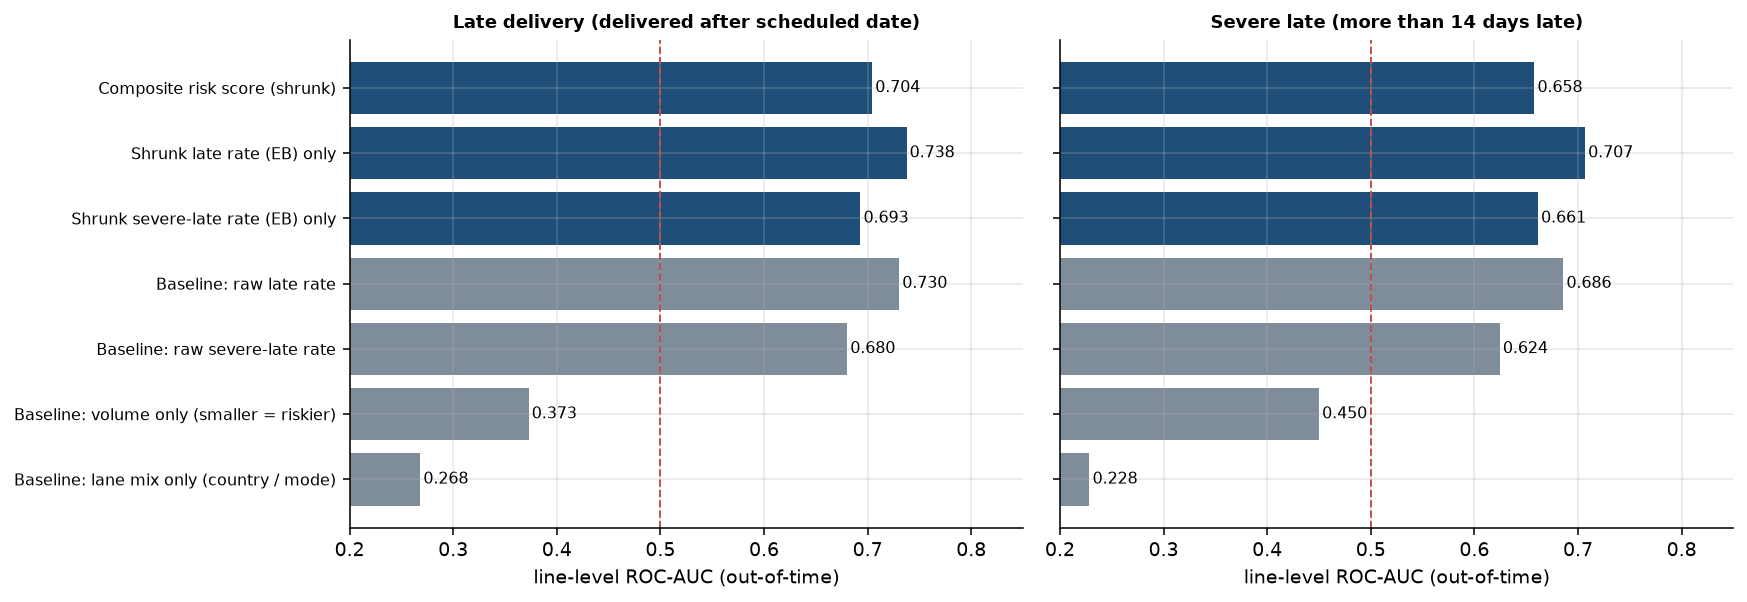

In [12]:
Image('docs/figures/oot_validation_auc.png', width=900)

**Reading:** with 21 evaluable vendors and 108 late lines the intervals are wide. The raw and EB-shrunk late rates rank next-period lateness at least as well as the composite in the main split; volume-only and lane-mix-only baselines rank the wrong way.

## 4. Cold start: New / unscored tier

In [13]:
pd.read_csv('artifacts/cold_start.csv').round(4)

,split,n_new_vendors,n_new_no_history,new_share_next_lines,new_share_next_value,new_lines,prior_mean_late,new_late,new_late_lo95,new_late_hi95,scored_late,prior_inside_ci,late_auc_scored_only,late_auc_full_coverage
0,2009-07-01->2011-07-01,21,10,0.1314,0.1560,141.0,0.0208,0.0213,0.0060,0.0557,0.1062,True,0.5814,0.5253
1,2010-07-01->2012-07-01,18,10,0.0784,0.0522,80.0,0.0259,0.0500,0.0171,0.1145,0.1160,True,0.5890,0.5979
2,2012-01-01->2016-01-01,28,18,0.1647,0.0238,436.0,0.0408,0.0023,0.0002,0.0107,0.0488,False,0.7375,0.7620
3,2013-01-01->2016-01-01,17,12,0.1826,0.0197,393.0,0.0392,0.0000,0.0000,0.0064,0.0478,False,0.7293,0.7558


## 5. Archetypes (indicative)

In [14]:
pd.read_csv('artifacts/cluster_selection.csv').round(3)

,k,silhouette,inertia,gmm_bic
0,2,0.434,99.156,360.552
1,3,0.487,58.630,250.657
2,4,0.483,41.845,272.242


In [15]:
pd.read_csv('artifacts/archetype_profiles.csv').round(3)

,archetype,n_vendors,value_usd,median_lines,late_rate_shrunk,mean_days_late,freight_ratio,air_share,country_hhi,risk_score,value_at_risk,value_share
0,Chronic late deliverers,3,2.787458e+08,668.0,0.127,4.346,0.056,0.728,0.179,76.552,3.609139e+07,0.514
1,Air-dependent,18,2.438969e+08,67.5,0.018,0.698,0.060,1.000,0.234,44.483,3.889283e+06,0.450
2,Surface / truck-based,3,1.101503e+07,326.0,0.016,0.346,0.067,0.000,1.000,38.448,1.657277e+05,0.020


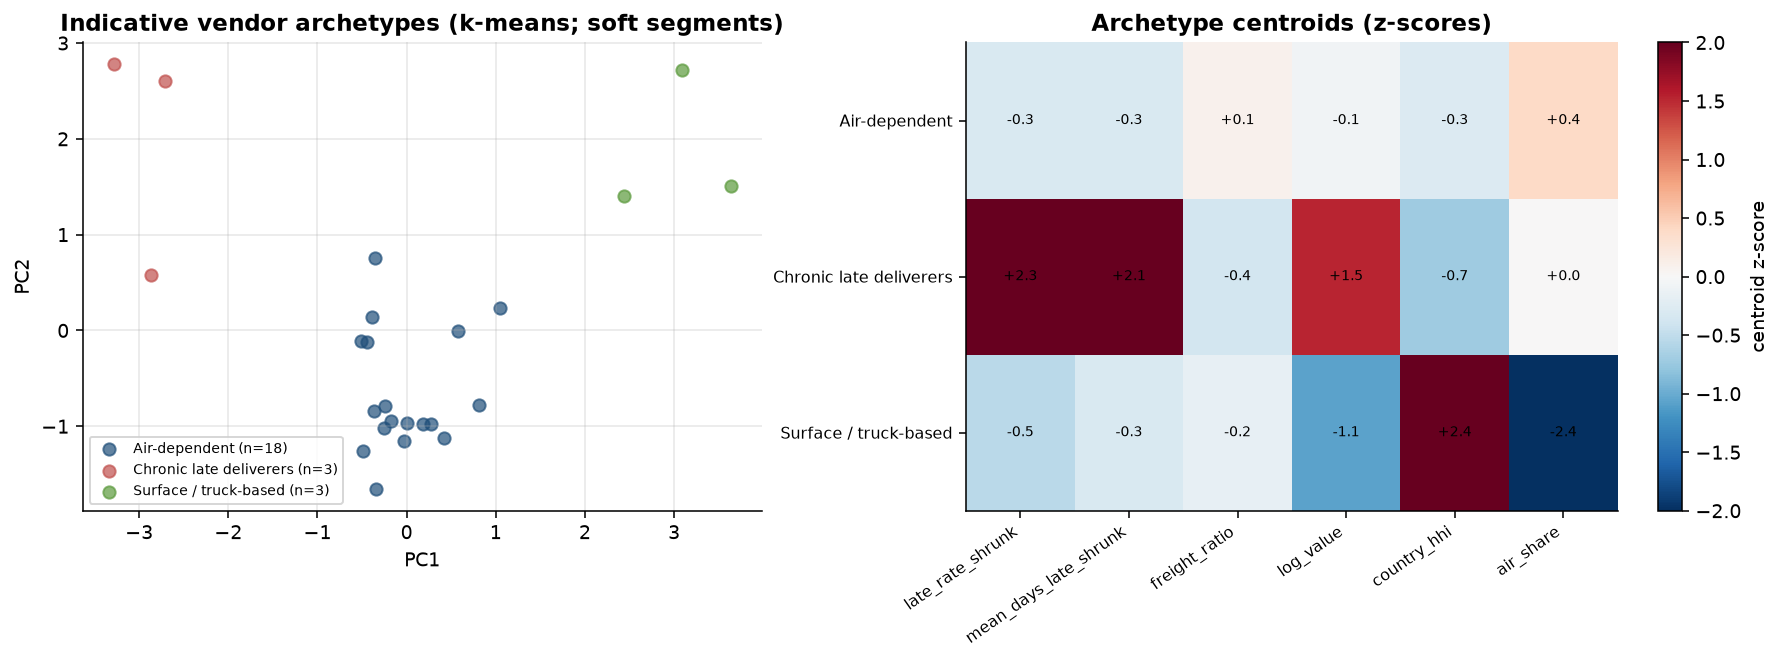

In [16]:
Image('docs/figures/vendor_archetypes.png', width=900)

## 6. Exposure and scenario (ASSUMED parameters)

In [17]:
{k: round(v) if v > 10 else round(v, 3) for k, v in t['exposure_totals'].items()}

{'value_usd': 542212022,
 'late_value_usd': 56501133,
 'value_at_risk': 40413451,
 'wc_excess_delay': 3536116,
 'total_exposure_ASSUMED': 2278874,
 'scored_value_share': 0.99,
 'top10pct_value_at_risk_share': 0.949,
 'top10pct_value_share': 0.822}

In [18]:
pd.DataFrame([t['scenario_base_ASSUMED'], t['scenario_raw_baseline_ASSUMED']], index=['composite ranking','raw late-rate ranking']).T

,composite ranking,raw late-rate ranking
top_share,2.000000e-01,2.000000e-01
realloc_frac,5.000000e-01,5.000000e-01
improvement_ASSUMED,5.000000e-01,5.000000e-01
n_top_vendors,4.000000e+00,4.000000e+00
top_value_share,1.544753e-01,5.050390e-01
top_late_rate_value,8.791728e-02,1.766614e-01
rest_late_rate_value,9.640833e-02,1.187118e-02
moved_value,2.039282e+07,6.667196e+07
late_value_before,2.510809e+07,2.510809e+07
late_value_avoided,0.000000e+00,5.493444e+06


In [19]:
pd.read_csv('artifacts/exposure_sensitivity.csv').round(3)

,late_cost_pct_of_value,carrying_rate_annual,total_exposure_ASSUMED,top_decile_risk_exposure_ASSUMED,top_decile_share
0,0.02,0.05,933260.884,429437.950,0.460
1,0.02,0.10,1061544.190,509918.068,0.480
2,0.02,0.20,1318110.802,670878.303,0.509
3,0.05,0.05,2140727.251,952874.700,0.445
4,0.05,0.10,2269010.557,1033354.817,0.455
5,0.05,0.20,2525577.169,1194315.052,0.473
6,0.10,0.05,4153171.197,1825269.282,0.439
7,0.10,0.10,4281454.503,1905749.399,0.445
8,0.10,0.20,4538021.115,2066709.634,0.455


## 7. R layer summary

In [20]:
json.load(open('artifacts/r_glm/r_summary.json'))

{'n_lines': 4920,
 'n_late': 259,
 'late_rate': 0.05264228,
 'n_vendors': 72,
 'glm_auc': 0.87853742,
 'lrt_year_dev': 20.08329867,
 'lrt_year_p': 0.00016313,
 'hosmer_lemeshow_stat': 9.2267939,
 'hosmer_lemeshow_p': 0.32352677,
 'max_gvif_adj': 2.91257727,
 'or_year_2013_15': 1.081,
 'or_year_2006_08': 0.65544,
 'or_truck': 0.22258,
 'or_hrdt': 1.7301,
 'or_ddp': 0.524,
 'or_internal_rdc_vs_vendor': 8.23705485,
 'or_internal_rdc_lo': 6.63650927,
 'or_internal_rdc_hi': 10.31204077,
 'glmm_n_lines': 4856,
 'glmm_n_vendors': 36,
 'glmm_vendor_sd_null': 1.2468818,
 'glmm_icc_null': 0.32091811,
 'glmm_vendor_sd': 1.12573483,
 'glmm_icc': 0.27808603,
 'glmm_mor': 2.92650114,
 'glmm_lr_vendor': 96.50176114,
 'glmm_p_vendor_boundary': 4.45822437e-23,
 'glmm_singular': False,
 'glmm_ship_n': 3529,
 'glmm_ship_icc': 0.23643343,
 'glmm_ship_vendor_sd': 1.00929991,
 'nb_n_late_lines': 259,
 'nb_theta': 0.83496528,
 'poisson_dispersion': 25.71489303,
 'irr_truck': 0.069544,
 'irr_hrdt': 2.3446,
 '